# Notebook setup

In [56]:
!which python

/home/maddy/Desktop/Projects/Iris_Dataset/.venv/bin/python


In [57]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [58]:
#Standard imports
import os

#Third party imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_val_predict

#Local imports

In [59]:
sns.set()

# **Load data**
Load iris flower dataset using sklearn's dataset

In [60]:
data = datasets.load_iris()

In [61]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [62]:
print(data.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [63]:
data["data"][:5]

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2]])

In [64]:
data["feature_names"]

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

## Problem to solve:
Use the attributes of flowers to predict the species of the flower. Specifically using the sepal length & width and petal length & width if the iris flower is of type setosa, versicolour or virginica.

This is a multiclass classification problem.

# Create pandas DataFrame from the data
analyse using pandas to make things simpler

In [65]:
df = pd.DataFrame(data=data["data"], columns = data["feature_names"])

In [66]:
df["target"] = data["target"]

In [67]:
df.head()

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

# Basic descriptive stats

In [68]:
df.describe()

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  

# **Relationship of the data features with the target**

In [69]:
# New column with the species name
df['target_name'] = df['target'].map({0: "setosa", 1: 'versicolour', 2: 'virginica'})

# EDA - Pairplots

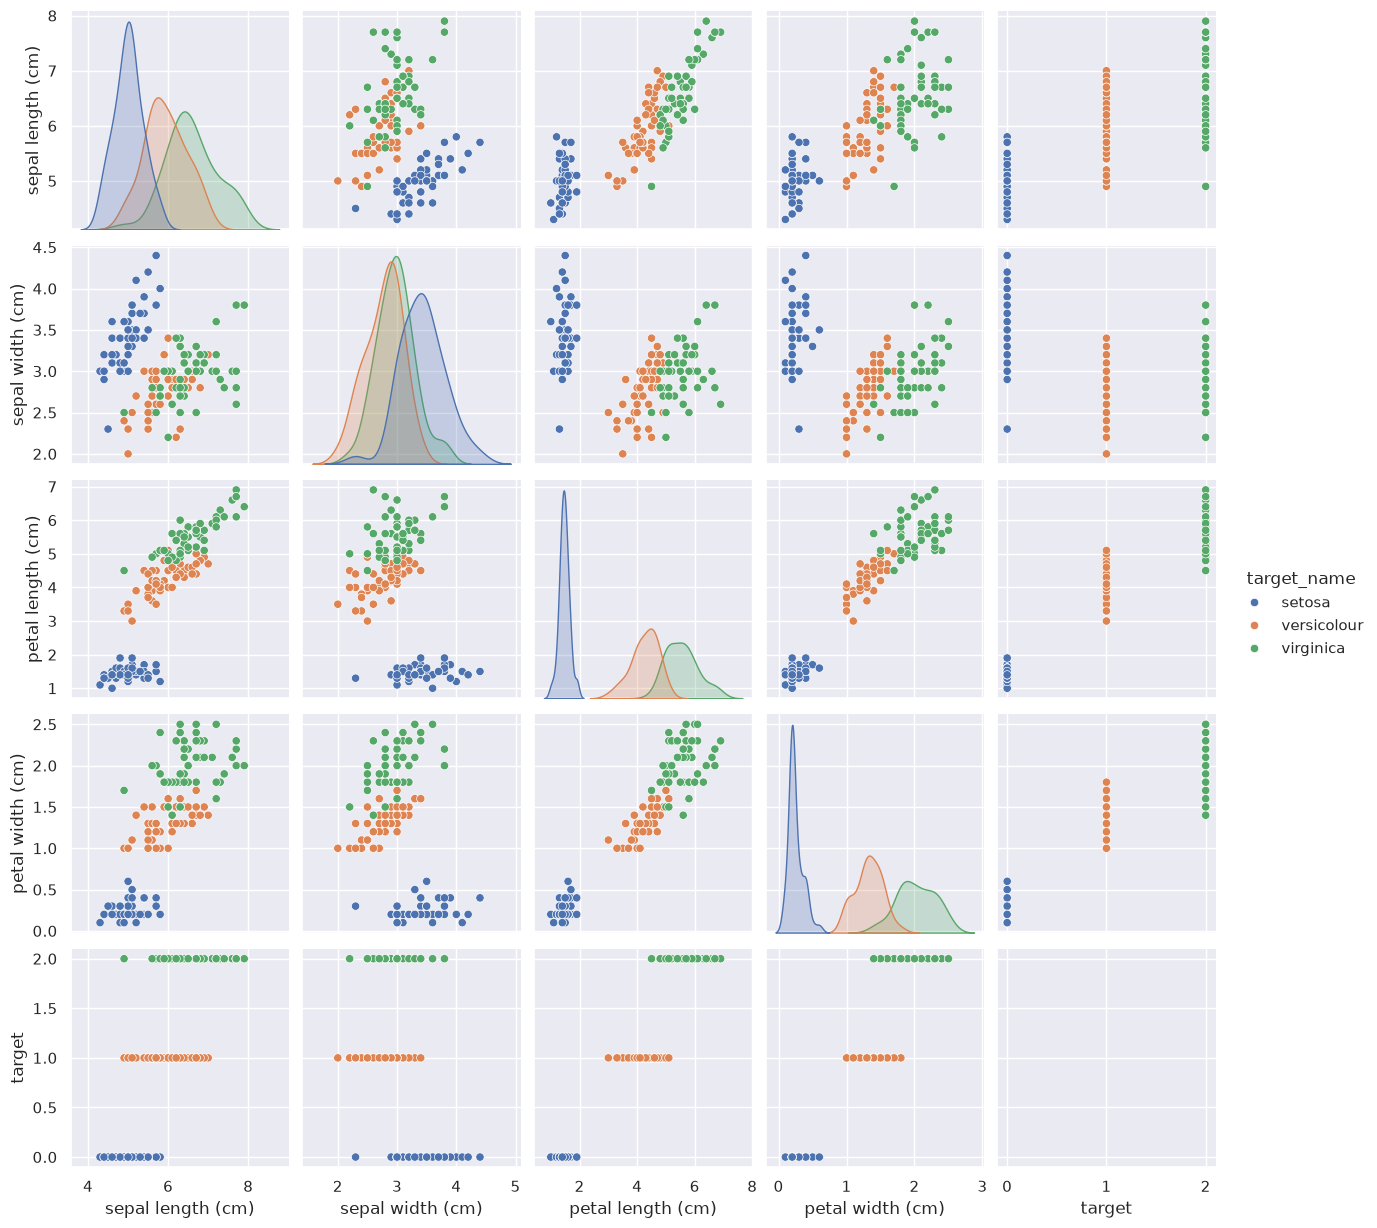

In [70]:
sns.pairplot(df, hue = "target_name")

# Train test Split

In [71]:
df_train, df_test = train_test_split(df, test_size = 0.25)

In [72]:
df_train.head()

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
116                6.5               3.0                5.5               1.8   
34                 4.9               3.1                1.5               0.2   
11                 4.8               3.4                1.6               0.2   
144                6.7               3.3                5.7               2.5   
3                  4.6               3.1                1.5               0.2   

     target target_name  
116       2   virginica  
34        0      setosa  
11        0      setosa  
144       2   virginica  
3         0      setosa  

# Prepare data for modeling
split data back into NumPy arrays

In [73]:
X_train = df_train.drop(columns = ["target", "target_name"]).values
y_train = df_train["target"].values

# Modeling - What is the baseline?

What is the simplest model we can think of?

-> Randomly guessing species of flowers: accuracy will be 33% (due to 3 different classes)

-> The ML model must at least beat 33% accuracy

## Manual model

Look at data manually and decide some cutoff points for classification

In [74]:
data["target_names"]

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [75]:
def single_feature_pred(petal_length):
    """ Predict iris species with petal length """
    if petal_length < 2.5:
        return 0
    elif petal_length < 4.8:
        return 1
    else:
        return 2

In [76]:
X_train[:, 2]

array([5.5, 1.5, 1.6, 5.7, 1.5, 4.4, 4.2, 5. , 4.3, 5.1, 1.3, 5.4, 1.4,
       4.5, 4.2, 6.7, 1.4, 6.9, 1. , 1.5, 4.2, 4.6, 5.6, 4.5, 1.3, 5.2,
       4.5, 1.4, 1.6, 1.4, 4.7, 5.6, 1.5, 1.5, 3.6, 1.1, 5.1, 4.8, 5.9,
       1.6, 1.4, 1.3, 1.5, 1.4, 1.4, 4.1, 4.5, 1.4, 3.9, 4.9, 6.1, 5.1,
       6.1, 4.8, 1.9, 1.5, 5.1, 4.7, 5.6, 5.6, 1.5, 3. , 5.4, 4.6, 1.5,
       5.3, 1.6, 5.8, 5. , 5.6, 5. , 4.1, 5.5, 4.9, 5.1, 5.1, 1.6, 4.9,
       1.9, 1.2, 6. , 6. , 1.5, 3.8, 4.7, 4. , 5.5, 1.3, 4.8, 4. , 4.5,
       5.6, 1.6, 4.4, 4.5, 1.3, 5.3, 1.7, 1.3, 6.7, 4.1, 1.2, 5.8, 4.3,
       6.1, 4.9, 1.4, 1.4, 3.3, 3.7, 1.6, 4. ])

In [77]:
manual_y_pred = np.array([single_feature_pred(val) for val in X_train[:,2]])
print(manual_y_pred)

[2 0 0 2 0 1 1 2 1 2 0 2 0 1 1 2 0 2 0 0 1 1 2 1 0 2 1 0 0 0 1 2 0 0 1 0 2
 2 2 0 0 0 0 0 0 1 1 0 1 2 2 2 2 2 0 0 2 1 2 2 0 1 2 1 0 2 0 2 2 2 2 1 2 2
 2 2 0 2 0 0 2 2 0 1 1 1 2 0 2 1 1 2 0 1 1 0 2 0 0 2 1 0 2 1 2 2 0 0 1 1 0
 1]


In [78]:
manual_acc = np.mean(manual_y_pred == y_train)

In [79]:
print(f"Manual model accuarcy: {manual_acc *100: .2f}%")

Manual model accuarcy:  97.32%


# Logistic Regression Model


In [80]:
model = LogisticRegression(max_iter= 75)

In [81]:
model.fit(X_train, y_train)

/home/maddy/Desktop/Projects/Iris_Dataset/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 75 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=75).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",75
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [82]:
X_test = df_test.drop(columns= ['target','target_name']).values
y_test = df_test['target'].values

### Using validation to evaluate the model

In [83]:
Xt, Xv, yt, yv = train_test_split(X_train, y_train, test_size = 0.25)

In [84]:
model.fit(Xt, yt)

/home/maddy/Desktop/Projects/Iris_Dataset/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 75 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=75).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",75
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [85]:
y_pred = model.predict(Xv)

In [86]:
np.mean(y_pred == yv)

np.float64(1.0)

In [87]:
model.score(Xv, yv)

1.0

## Cross validation on our model

In [88]:
model = LogisticRegression(max_iter = 200)

In [89]:
accuracies = cross_val_score(model,X_train, y_train, cv= 5, scoring='accuracy')

In [90]:
np.mean(accuracies)

np.float64(0.9731225296442687)

## Where are the misclassifications?

In [91]:
y_pred = cross_val_predict(model, X_train, y_train, cv = 5)

In [92]:
predicted_correctly_mask = y_pred == y_train

In [93]:
#Predicted correctly
X_train[predicted_correctly_mask]

array([[6.5, 3. , 5.5, 1.8],
       [4.9, 3.1, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [6.7, 3.3, 5.7, 2.5],
       [4.6, 3.1, 1.5, 0.2],
       [6.6, 3. , 4.4, 1.4],
       [5.9, 3. , 4.2, 1.5],
       [6.3, 2.5, 5. , 1.9],
       [6.4, 2.9, 4.3, 1.3],
       [5.8, 2.7, 5.1, 1.9],
       [5.4, 3.9, 1.3, 0.4],
       [6.2, 3.4, 5.4, 2.3],
       [5.5, 4.2, 1.4, 0.2],
       [5.7, 2.8, 4.5, 1.3],
       [5.7, 3. , 4.2, 1.2],
       [7.7, 3.8, 6.7, 2.2],
       [4.4, 2.9, 1.4, 0.2],
       [7.7, 2.6, 6.9, 2.3],
       [4.6, 3.6, 1. , 0.2],
       [5.3, 3.7, 1.5, 0.2],
       [5.6, 2.7, 4.2, 1.3],
       [6.5, 2.8, 4.6, 1.5],
       [6.1, 2.6, 5.6, 1.4],
       [6. , 3.4, 4.5, 1.6],
       [4.4, 3. , 1.3, 0.2],
       [6.7, 3. , 5.2, 2.3],
       [5.4, 3. , 4.5, 1.5],
       [5. , 3.6, 1.4, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.1, 3.5, 1.4, 0.3],
       [6.1, 2.8, 4.7, 1.2],
       [6.3, 2.9, 5.6, 1.8],
       [5.4, 3.4, 1.5, 0.4],
       [4.9, 3.1, 1.5, 0.1],
       [5.6, 2

In [94]:
not_predicted_correctly_mask = ~predicted_correctly_mask

In [95]:
X_train[not_predicted_correctly_mask]

array([[6. , 2.7, 5.1, 1.6],
       [6. , 2.2, 5. , 1.5],
       [6.3, 2.5, 4.9, 1.5]])

In [96]:
df_predictions = df_train.copy()

In [97]:
df_predictions["correct_prediction"] = predicted_correctly_mask

In [98]:
df_predictions["prediction"] = y_pred
df_predictions.head()

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
116                6.5               3.0                5.5               1.8   
34                 4.9               3.1                1.5               0.2   
11                 4.8               3.4                1.6               0.2   
144                6.7               3.3                5.7               2.5   
3                  4.6               3.1                1.5               0.2   

     target target_name  correct_prediction  prediction  
116       2   virginica                True           2  
34        0      setosa                True           0  
11        0      setosa                True           0  
144       2   virginica                True           2  
3         0      setosa                True           0  

In [99]:
df_predictions["prediction_label"] = df_predictions["prediction"].map({0:"setosa", 1: "versicolour", 2: "virginica"})

In [100]:
df_predictions.head()

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
116                6.5               3.0                5.5               1.8   
34                 4.9               3.1                1.5               0.2   
11                 4.8               3.4                1.6               0.2   
144                6.7               3.3                5.7               2.5   
3                  4.6               3.1                1.5               0.2   

     target target_name  correct_prediction  prediction prediction_label  
116       2   virginica                True           2        virginica  
34        0      setosa                True           0           setosa  
11        0      setosa                True           0           setosa  
144       2   virginica                True           2        virginica  
3         0      setosa                True           0           setosa  

<Axes: xlabel='petal length (cm)', ylabel='petal width (cm)'>

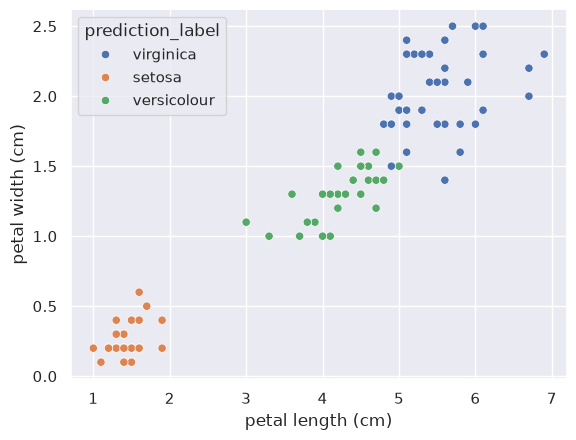

In [101]:
sns.scatterplot(x="petal length (cm)", y = "petal width (cm)", data = df_predictions, hue="prediction_label")

<Axes: xlabel='petal length (cm)', ylabel='petal width (cm)'>

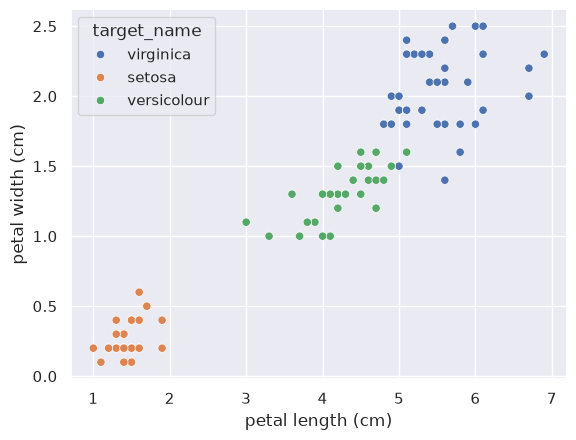

In [102]:
sns.scatterplot(x="petal length (cm)", y = "petal width (cm)", data = df_predictions, hue="target_name")

In [103]:
def plot_incorrect_predictions(df_predictions, x_axis_feature, y_axis_feature):
    fig, axs = plt.subplots(2,2, figsize = (10,10))
    axs =axs.flatten()
    sns.scatterplot(x = x_axis_feature, y = y_axis_feature, hue = "prediction_label", data = df_predictions, ax = axs[0])
    sns.scatterplot(x = x_axis_feature, y = y_axis_feature, hue = "target_name", data = df_predictions, ax = axs[1])
    sns.scatterplot(x = x_axis_feature, y = y_axis_feature, hue = "correct_prediction", data = df_predictions, ax = axs[2])
    axs[3].set_visible(False)
    plt.show()

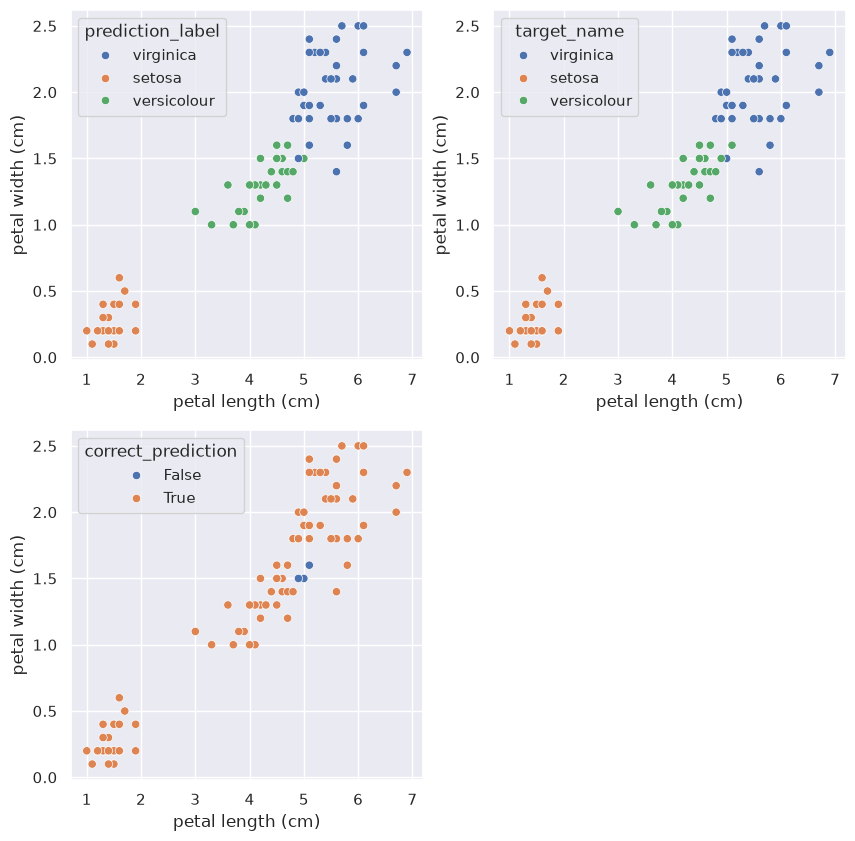

In [104]:
plot_incorrect_predictions(df_predictions, "petal length (cm)", "petal width (cm)")

# Model Tuning

In [105]:
for reg_param in (0.001,0.01,0.1,1,10,100):
    print(reg_param)
    model = LogisticRegression(max_iter = 200, C = reg_param)
    accuracies = cross_val_score(model, X_train, y_train, cv = 5, scoring="accuracy")
    print(f"Accuracy: {np.mean(accuracies) * 100:.2f}%")

0.001
Accuracy: 70.55%
0.01
Accuracy: 75.97%
0.1
Accuracy: 94.58%
1
Accuracy: 97.31%
10
Accuracy: 97.31%
100
Accuracy: 97.35%


# Final Model

In [106]:
model = LogisticRegression(max_iter = 200, C=10)


In [107]:
model.fit(X_train, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [108]:
y_test_pred = model.predict(X_test)

In [109]:
correct_classified = (y_test_pred == y_test)
accuracy_model = np.mean(correct_classified)

In [110]:
print(f"test set accuracy {accuracy_model *100:.2f}%")

test set accuracy 94.74%
